# Milestone 4 · Notebook 1c: The Start-of-Clip Click

**Project:** Deepfake Voice Detection for Indian Languages · Group-3

In Milestone 3 we noticed a sharp peak about 47 ms into real Kathbath recordings, about 7 ms after silence trimming.
This notebook checks whether it is still in the Milestone-4 data and whether a model could use it to tell real from
fake, removes it, and checks again.

**The fix** is a new preprocessing step in `src/preprocess.py`, applied to every clip of every source and split:
after trimming edge silence, cut the first 30 ms and trim again. The first trim stops at the click (it is the first
loud frame), so the click always sits in the first few milliseconds of a trimmed clip.

The stored clips of notebooks 1 and 1b are updated in place: each is cut and re-trimmed from its stored file; the clips
whose original file was kept are rebuilt from the original with the updated `src/preprocess.py`; and the phone-channel
test clips are made again from the updated in-domain clips. New clips (for example the full test sets of Milestone 5)
get the step directly from `src/preprocess.py`.

## 1. Setup

In [1]:
import os
import sys
import zlib
from multiprocessing import Pool
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO))
from src.augment import phone_channel
from src.preprocess import MIN_SECONDS, TARGET_SR, cut_start, normalise, sha1, to_pcm16

DATA = REPO / "data" / "m4"
MANIFESTS = DATA / "manifests"
FIGURES = REPO / "assets" / "infographics" / "Milestone-4"
FIGURES.mkdir(parents=True, exist_ok=True)
FFMPEG = __import__("shutil").which("ffmpeg") or __import__("imageio_ffmpeg").get_ffmpeg_exe()
SEED = 42

manifest = pd.read_csv(MANIFESTS / "manifest_m4.csv", keep_default_na=False,
                       dtype={"speaker_id": str, "ref_speaker_id": str})
print(f"{len(manifest):,} clips")

37,892 clips


## 2. Tests for the Click

- **Envelope:** the mean loudness of the first 200 ms of real and fake training clips.
- **Click rate:** the share of clips with a peak above 0.3 between 4 and 12 ms, per split and source.
- **Shortcut test:** a logistic regression that sees only 20 ms of each clip (the mean and the maximum loudness in
  2 ms steps) and is asked for real or fake, with 5-fold cross-validation. ROC AUC 0.5 means the 20 ms carry no
  label information; 1.0 means they give it away completely.

In [2]:
indian_train = manifest[(manifest.split == "train") & manifest.language.isin(["hi", "ta", "te"])]
probe = pd.concat([indian_train[indian_train.label == label].sample(600, random_state=1) for label in ("real", "fake")])


def envelopes(rows):
    env = {}
    for label in ("real", "fake"):
        heads = [np.pad(sf.read(DATA / p, dtype="float32", frames=3200)[0], (0, 3200))[:3200]
                 for p in rows[rows.label == label].path]
        env[label] = np.abs(np.stack(heads)).reshape(len(heads), -1, 16).mean(axis=(0, 2))  # 1 ms steps
    return env


def window_auc(rows, start_ms, from_end=False, length_ms=20):
    n, a = int(TARGET_SR * length_ms / 1000), int(TARGET_SR * start_ms / 1000)
    features = []
    for p in rows.path:
        x, _ = sf.read(DATA / p, dtype="float32")
        seg = np.abs(x[len(x) - n:] if from_end else x[a:a + n])
        seg = np.pad(seg, (0, n - len(seg)))
        features.append(np.concatenate([seg.reshape(-1, 32).mean(1), seg.reshape(-1, 32).max(1)]))
    X, y = np.log(np.stack(features) + 1e-6), (rows.label == "fake").to_numpy()
    return cross_val_score(LogisticRegression(max_iter=3000), X, y, cv=5, scoring="roc_auc").mean()


def click_rates(frame):
    out = []
    for (split, dataset, label), g in frame.groupby(["split", "dataset", "label"], observed=True):
        g = g.sample(min(200, len(g)), random_state=0)
        hits = [np.abs(sf.read(DATA / p, dtype="float32", frames=192)[0][64:]).max(initial=0) > 0.3 for p in g.path]
        out.append({"split": split, "dataset": dataset, "label": label, "click rate": np.mean(hits)})
    return pd.DataFrame(out)


def shortcut_table(rows):
    return pd.Series({f"20 ms from {s} ms": window_auc(rows, s) for s in (0, 10, 30, 100)}
                     | {"last 20 ms": window_auc(rows, 0, from_end=True)}).round(3).rename("ROC AUC")

## 3. Before the Fix

In [3]:
before_env = envelopes(probe)
before_auc = shortcut_table(probe)
before_rates = click_rates(manifest[manifest.split != "test_phone"])
before_auc

20 ms from 0 ms      1.000
20 ms from 10 ms     0.903
20 ms from 30 ms     0.870
20 ms from 100 ms    0.735
last 20 ms           0.771
Name: ROC AUC, dtype: float64

In [4]:
before_rates.pivot_table(index=["split", "dataset"], columns="label", values="click rate").map(lambda v: f"{v:.0%}")

label                            fake  real
split           dataset                    
test_asvspoof   asvspoof2019_la    2%    2%
test_indomain   indicsynth         0%  nan%
                kathbath         nan%   98%
test_itw        in_the_wild        0%    0%
test_unseen_gen generated          0%  nan%
                kathbath         nan%   98%
train           asvspoof2019_la    0%    0%
                indicsynth         0%  nan%
                kathbath         nan%   97%
valid           asvspoof2019_la    0%    0%
                indicsynth         0%  nan%
                kathbath         nan%  100%

**Before:** almost every real Kathbath clip, in every split (including the Kathbath test speakers of the unseen-generator
test), starts with the click, and no fake source has it. 20 ms from the start of a clip are enough to tell real from
fake perfectly. In-the-Wild and ASVspoof have no click in either class.

## 4. The Fix

Every stored clip except the phone-channel clips is cut and re-trimmed. Clips that become shorter than 1 s are dropped
(and listed in `dropped.csv`).

In [5]:
def fix(row):
    """Updated (int16 samples or None, clip id) for one stored clip."""
    clip_id, path, raw_path = row
    if raw_path:  # the original is kept: rebuild it with the updated preprocessing
        pcm, _ = to_pcm16((DATA / raw_path).read_bytes())
    else:
        stored, _ = sf.read(DATA / path, dtype="int16")
        audio = cut_start(stored.astype(np.float32) / 32768)
        pcm = None if len(audio) < MIN_SECONDS * TARGET_SR else np.round(normalise(audio) * 32767).astype(np.int16)
    if pcm is not None:
        sf.write(DATA / path, pcm, TARGET_SR, subtype="PCM_16")
    return clip_id, None if pcm is None else (round(len(pcm) / TARGET_SR, 3), sha1(pcm))


todo = manifest[manifest.split != "test_phone"]
with Pool(4) as pool:
    results = dict(pool.map(fix, todo[["clip_id", "path", "raw_path"]].itertuples(index=False, name=None), chunksize=64))
gone = [c for c, r in results.items() if r is None]
updated = pd.DataFrame([(c, *r) for c, r in results.items() if r is not None],
                       columns=["clip_id", "duration_s", "sha1"]).set_index("clip_id")
has = manifest.clip_id.isin(updated.index)
for column in ("duration_s", "sha1"):
    manifest.loc[has, column] = manifest.loc[has, "clip_id"].map(updated[column]).to_numpy()
print(f"{len(results):,} clips updated, {len(gone)} now shorter than 1 s")

36,892 clips updated, 96 now shorter than 1 s


In [6]:
dropped_now = manifest[manifest.clip_id.isin(gone)].assign(reason="shorter than 1 s after the start cut")
manifest = manifest[~manifest.clip_id.isin(gone)]
for clip_id in gone:
    path = DATA / dropped_now.set_index("clip_id").path[clip_id]
    path.unlink(missing_ok=True)

# the phone-channel clips again, from the updated in-domain clips (same codec choice per clip as notebook 1b)
indomain = manifest[manifest.split == "test_indomain"].set_index("clip_id")
phone = manifest[manifest.split == "test_phone"]
lost_phone = phone[~phone.clip_id.str.removeprefix("phone_").isin(indomain.index)].clip_id
for r in phone[~phone.clip_id.isin(lost_phone)].itertuples():
    wave, _ = sf.read(DATA / indomain.path[r.clip_id.removeprefix("phone_")], dtype="float32")
    codec_name = ("mulaw", "alaw")[zlib.crc32(r.clip_id.encode()) % 2]
    pcm = np.round(normalise(phone_channel(wave, TARGET_SR, codec_name, FFMPEG)) * 32767).astype(np.int16)
    sf.write(DATA / r.path, pcm, TARGET_SR, subtype="PCM_16")
    manifest.loc[manifest.clip_id == r.clip_id, ["duration_s", "sha1"]] = (round(len(pcm) / TARGET_SR, 3), sha1(pcm))
for path in phone[phone.clip_id.isin(lost_phone)].path:
    (DATA / path).unlink(missing_ok=True)
manifest = manifest[~manifest.clip_id.isin(lost_phone)]

manifest.to_csv(MANIFESTS / "manifest_m4.csv", index=False)
old = pd.read_csv(MANIFESTS / "dropped.csv", keep_default_na=False)
pd.concat([old, dropped_now.drop(columns=["path", "raw_path", "duration_s", "sha1", "tune_subset", "train_eval",
                                          "m4_eval"], errors="ignore")]).to_csv(MANIFESTS / "dropped.csv", index=False)
print(f"{len(phone) - len(lost_phone):,} phone clips made again; manifest now {len(manifest):,} clips")
manifest.groupby("split", observed=True).clip_id.count().rename("clips")

1,000 phone clips made again; manifest now 37,796 clips


split
test_asvspoof        949
test_indomain       1000
test_itw             942
test_phone          1000
test_unseen_gen     1000
train              28953
valid               3952
Name: clips, dtype: int64

## 5. After the Fix

In [7]:
probe = probe[probe.clip_id.isin(manifest.clip_id)]
after_env = envelopes(probe)
after_auc = shortcut_table(probe)
after_rates = click_rates(manifest)
pd.DataFrame({"before": before_auc, "after": after_auc})

,before,after
20 ms from 0 ms,1.000,0.799
20 ms from 10 ms,0.903,0.766
20 ms from 30 ms,0.870,0.678
20 ms from 100 ms,0.735,0.704
last 20 ms,0.771,0.731


In [8]:
pd.concat({"before": before_rates.set_index(["split", "dataset", "label"])["click rate"],
           "after": after_rates.set_index(["split", "dataset", "label"])["click rate"]}, axis=1).map(
    lambda v: "" if pd.isna(v) else f"{v:.0%}")

before after
split           dataset         label             
test_asvspoof   asvspoof2019_la fake      2%   22%
                                real      2%   10%
test_indomain   indicsynth      fake      0%    6%
                kathbath        real     98%    1%
test_itw        in_the_wild     fake      0%   10%
                                real      0%    4%
test_unseen_gen generated       fake      0%   18%
                kathbath        real     98%    0%
train           asvspoof2019_la fake      0%   20%
                                real      0%   12%
                indicsynth      fake      0%    4%
                kathbath        real     97%    2%
valid           asvspoof2019_la fake      0%   26%
                                real      0%    6%
                indicsynth      fake      0%    6%
                kathbath        real    100%    2%
test_phone      indicsynth      fake            4%
                kathbath        real            1%

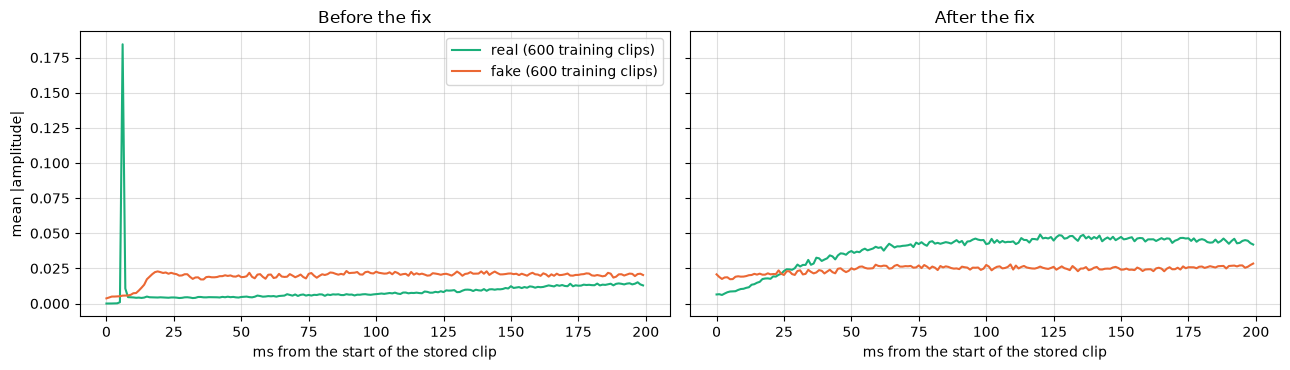

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (title, env) in zip(axes, [("Before the fix", before_env), ("After the fix", after_env)]):
    for label, color in [("real", "#1baf7a"), ("fake", "#eb6834")]:
        ax.plot(np.arange(len(env[label])), env[label], color=color, label=f"{label} (600 training clips)")
    ax.set(title=title, xlabel="ms from the start of the stored clip")
    ax.grid(True, alpha=0.4)
axes[0].set_ylabel("mean |amplitude|")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURES / "click_check.png", dpi=150)
plt.show()

In [10]:
leaks = {"duplicate clips (same SHA-1)": int(manifest.sha1.duplicated().sum()),
         "manifest rows without a file": int(sum(not (DATA / p).exists() for p in manifest.path))}
leaks

{'duplicate clips (same SHA-1)': 0, 'manifest rows without a file': 0}

## 6. Summary

- **The click was there:** 97–100% of real Kathbath clips started with it, in every split, including the Kathbath
  test speakers of the unseen-generator test. No fake source had it, and neither class of In-the-Wild or ASVspoof did.
- **It gave the label away:** 20 ms from the start of a clip separated real from fake with ROC AUC 1.000.
- **After the fix:** 0–2% of real Kathbath clips have a peak there, the same as the other sources, and the 20 ms
  shortcut drops to ROC AUC 0.80. That is close to the 0.70–0.73 that 20 ms from the middle or the end of a clip
  give, which comes from ordinary differences between the recordings (room noise, loudness over time), not a marker.
- **Clips:** 36,892 clips were updated, 96 became shorter than 1 s and were dropped, and the 1,000 phone-channel clips
  were made again. The manifest now has 37,796 clips. All 179 kept originals reproduce their stored clip exactly with
  the updated `src/preprocess.py`, no clip appears twice, and every manifest row has a file.

The updated data is uploaded as a new version of the Kaggle dataset `dsai-group3-m4-data`. Runs trained before this fix
(the Table A sweeps) used the data with the click; run T-01 is repeated on the fixed data to measure the difference.